# A15 措施实施后结果变好，真的是措施的作用吗？

用已知机制的模拟培训数据比较直接均值差、控制混杂后的估计与随机 A/B。使用 DoWhy 明确建模、识别、估计和安慰剂反驳；检验通过不等于证明因果。

先修：B10、B27；相关与因果、因果图、线性估计、bootstrap。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 明确目标效应与混杂机制
W 是原有经验，T 是是否参加培训，Y 是结果。经验同时影响参训与结果，直接比较培训组会混入经验差异。模拟真实平均效应设为 2，只用于核验教学代码；真实数据通常不知道这个答案。

In [2]:
import numpy as np,pandas as pd,json,warnings
from scipy.special import expit
from dowhy import CausalModel
rng=np.random.default_rng(115); n=1200
W=rng.normal(0,1,n); probability=expit(0.9*W)
T=rng.binomial(1,probability).astype(int)
Y=10+2*T+3*W+rng.normal(0,1,n)
data=pd.DataFrame({'experience':W,'training':T,'outcome':Y})
data.to_csv(DATA_DIR/'simulated_training.csv',index=False)
naive=float(data.loc[T==1,'outcome'].mean()-data.loc[T==0,'outcome'].mean())
graph='digraph { experience -> training; experience -> outcome; training -> outcome; }'
assumptions='经验是所有共同原因；无未测混杂；个体间无干扰；培训含义一致；每种经验附近都可能参训或不参训。'


## 2. 先识别，再估计
图来自机制假设，不由数据自动证明。DoWhy 先给出后门调整表达式，再调用线性回归估计。本例已知模拟图没有未测共同原因；另构造有未观测 U 的假设图，展示后门调整失败时停止估计。proceed_when_unidentifiable=True 只避免交互提示，不是允许强行得出因果结果。

In [3]:
causal_model=CausalModel(data=data,treatment='training',outcome='outcome',graph=graph)
estimand=causal_model.identify_effect(proceed_when_unidentifiable=True)
adjustment=estimand.get_backdoor_variables()
assert 'experience' in adjustment
estimate=causal_model.estimate_effect(estimand,method_name='backdoor.linear_regression')
adjusted=float(estimate.value)
(OUT_DIR/'identified_estimand.txt').write_text(str(estimand)+'\n\n假设：'+assumptions,encoding='utf-8')
unobserved_graph='digraph { experience -> training; experience -> outcome; training -> outcome; U -> training; U -> outcome; }'
unobserved_model=CausalModel(data=data,treatment='training',outcome='outcome',graph=unobserved_graph)
unobserved_estimand=unobserved_model.identify_effect(proceed_when_unidentifiable=True)
unobserved_backdoor_unidentified=unobserved_estimand.estimands.get('backdoor') is None
assert unobserved_backdoor_unidentified
(OUT_DIR/'unidentified_scenario.txt').write_text(str(unobserved_estimand)+'\n\nU 未被测量，当前图下不能用已观测变量完成后门调整；不继续调用估计器，应收集共同原因或设计随机试验。',encoding='utf-8')
print('直接均值差',naive,'后门调整',adjusted)


直接均值差 4.268001388583295 后门调整 1.9330444797805697


[课程目录]\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
[课程目录]\.venv\Lib\site-packages\dowhy\causal_model.py:581: UserWarning: 1 variables are assumed unobserved because they are not in the dataset. Configure the logging level to `logging.WARNING` or higher for additional details.
  warnings.warn(


## 3. 安慰剂、抽样不确定性与随机 A/B
打乱培训标签后应不再保留原来的效应，这是可反驳检查而非因果证明。为控制练习时长，只运行 10 次安慰剂和 250 次 bootstrap；次数仅适合演示，不能把小规模检验结果当充分证据。对独立行重抽样重算系数，区间只描述抽样不确定性；另生成随机参训数据，展示随机化减少系统性混杂。

In [4]:
refutation=causal_model.refute_estimate(estimand,estimate,method_name='placebo_treatment_refuter',placebo_type='permute',num_simulations=10,random_seed=115,n_jobs=1,show_progress_bar=False)
placebo=float(np.asarray(refutation.new_effect).mean())
def adjusted_coefficient(frame):
    design=np.column_stack([np.ones(len(frame)),frame['training'],frame['experience']])
    return float(np.linalg.lstsq(design,frame['outcome'],rcond=None)[0][1])
bootstrap=[]
boot_rng=np.random.default_rng(116)
for _ in range(250):
    bootstrap.append(adjusted_coefficient(data.iloc[boot_rng.integers(0,n,n)]))
interval=np.quantile(bootstrap,[0.025,0.975])
ab_t=rng.binomial(1,0.5,n)
ab_y=10+2*ab_t+3*W+rng.normal(0,1,n)
ab_effect=float(ab_y[ab_t==1].mean()-ab_y[ab_t==0].mean())
(OUT_DIR/'refutation.txt').write_text(str(refutation)+'\n\n通过反驳检验不证明识别假设成立。',encoding='utf-8')


[课程目录]\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
[课程目录]\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
[课程目录]\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a v

[课程目录]\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
[课程目录]\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]


## 4. 用偏差情景说明未测混杂的风险
假设遗漏变量在两组条件均值差为 delta，对结果作用为 gamma，则线性加性情景下偏差为 gamma×delta。扫描假设强度，观察结论何时翻转；不是从数据估出了隐藏变量。若真实图还有未测共同原因且无其他识别设计，应停止因果估计并提出随机试验。

In [5]:
sensitivity_rows=[{'gamma':g,'delta':d,'assumed_bias':g*d,'bias_adjusted_effect':adjusted-g*d} for g in [0,1,2,3,4] for d in [0,0.5,1]]
sensitivity=pd.DataFrame(sensitivity_rows)
metrics={'true_effect_in_simulator':2,'naive_difference':naive,'adjusted_effect':adjusted,'bootstrap_interval_95':[float(v) for v in interval],'randomized_ab_difference':ab_effect,'placebo_effect':placebo,'adjustment_variables':adjustment,'assumptions':assumptions,'refutation_is_proof':False,'unobserved_scenario_backdoor_unidentified':unobserved_backdoor_unidentified}
sensitivity.to_csv(OUT_DIR/'unmeasured_bias_scenarios.csv',index=False)
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
advice=f'直接比较得到 {naive:.3f}，按经验调整后为 {adjusted:.3f}，独立样本 bootstrap 95% 区间 [{interval[0]:.3f},{interval[1]:.3f}]；随机 A/B 对照为 {ab_effect:.3f}，安慰剂为 {placebo:.3f}。这些是已知模拟图的演示。采用因果解释前必须支持“{assumptions}”。反驳通过不等于证明，隐藏偏差达到估计量大小时正效应可能消失；真实项目应优先收集共同原因或安排随机试验。'
(OUT_DIR/'决策建议.md').write_text('# 因果分析建议\n\n'+advice,encoding='utf-8')
plt.bar(['直接均值差','调整估计','随机A/B','安慰剂'],[naive,adjusted,ab_effect,placebo]); plt.axhline(2,ls='--',color='grey',label='模拟真实效应'); plt.ylabel('效果 / 教学单位'); plt.legend(); plt.tight_layout(); plt.savefig(OUT_DIR/'causal_comparison.png'); plt.close(); print(metrics)


{'true_effect_in_simulator': 2, 'naive_difference': 4.268001388583295, 'adjusted_effect': 1.9330444797805697, 'bootstrap_interval_95': [1.8181928635063824, 2.0672562933721235], 'randomized_ab_difference': 2.064872763941141, 'placebo_effect': -0.014134005105778336, 'adjustment_variables': ['experience'], 'assumptions': '经验是所有共同原因；无未测混杂；个体间无干扰；培训含义一致；每种经验附近都可能参训或不参训。', 'refutation_is_proof': False, 'unobserved_scenario_backdoor_unidentified': True}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

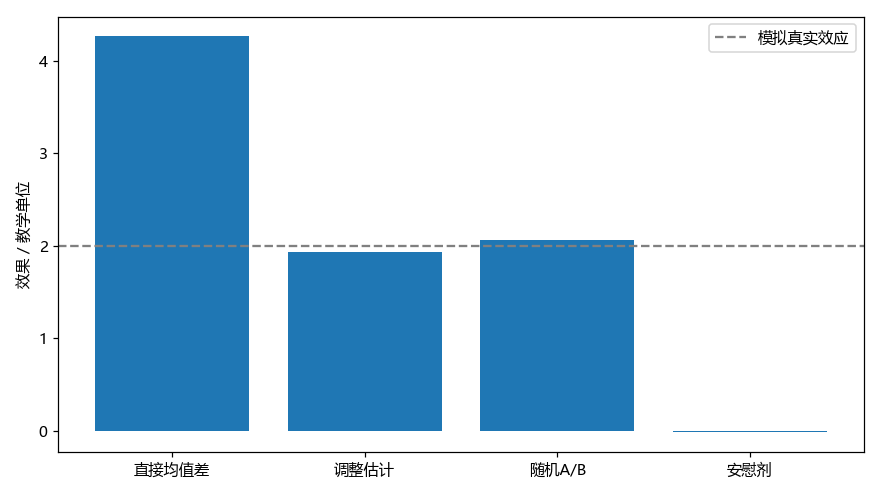

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
identify 返回表达式只说明在输入图与假设下可识别；图可能错误。反驳检验通过不能验证没有未测混杂，bootstrap 也不涵盖识别假设错误。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。